In [1]:
# Welcome to your new notebook
# Type here in the cell editor to add code!

from pyspark.sql import functions as F

# Load hospital-level quarterly clinical indicators
df_hospital = spark.table("gold_ed_hospital_quarterly")

# Check dimensions and schema
print("Total records:", df_hospital.count())
print("Total columns:", len(df_hospital.columns))

df_hospital.printSchema()

display(df_hospital.limit(5))


StatementMeta(, bfda8732-6913-4bf0-872c-1a1814fd5025, 3, Finished, Available, Finished, False)

Total records: 1155
Total columns: 12
root
 |-- facility_code: integer (nullable = true)
 |-- facility_name: string (nullable = true)
 |-- reporting_quarter: string (nullable = true)
 |-- quarter_end_month: date (nullable = true)
 |-- total_attendances: integer (nullable = true)
 |-- seen_within_target_pct: double (nullable = true)
 |-- median_wait_minutes: double (nullable = true)
 |-- did_not_wait_pct: double (nullable = true)
 |-- admitted_from_ed_pct: double (nullable = true)
 |-- admissions_within_4h_pct: double (nullable = true)
 |-- ed_stay_within_4h_pct: double (nullable = true)
 |-- source_file: string (nullable = true)



SynapseWidget(Synapse.DataFrame, 0619da58-b650-4075-a0ba-5d36b8bf2402)

In [3]:
from pyspark.sql import functions as F
from pyspark.sql.types import (
    StructType, StructField,
    StringType, DoubleType
)

# Select Toowoomba Hospital
df_toowoomba = df_hospital.filter(
    F.col("facility_code") == 104
)

print("Toowoomba reporting quarters:", df_toowoomba.count())

indicators = [
    "total_attendances",
    "seen_within_target_pct",
    "median_wait_minutes",
    "ed_stay_within_4h_pct"
]

statistics = []

for indicator in indicators:

    result = df_toowoomba.agg(
        F.avg(indicator).alias("mean"),
        F.expr(
            f"percentile_approx({indicator}, 0.5)"
        ).alias("median"),
        F.stddev_samp(indicator).alias("std_dev"),
        F.min(indicator).alias("minimum"),
        F.max(indicator).alias("maximum")
    ).first()

    statistics.append((
        indicator,
        float(result["mean"]) if result["mean"] is not None else None,
        float(result["median"]) if result["median"] is not None else None,
        float(result["std_dev"]) if result["std_dev"] is not None else None,
        float(result["minimum"]) if result["minimum"] is not None else None,
        float(result["maximum"]) if result["maximum"] is not None else None
    ))

# Explicit schema prevents LongType/DoubleType conflicts
schema = StructType([
    StructField("indicator", StringType(), False),
    StructField("mean", DoubleType(), True),
    StructField("median", DoubleType(), True),
    StructField("std_dev", DoubleType(), True),
    StructField("minimum", DoubleType(), True),
    StructField("maximum", DoubleType(), True)
])

df_statistics = spark.createDataFrame(
    statistics,
    schema=schema
)

display(
    df_statistics.select(
        "indicator",
        F.round("mean", 2).alias("mean"),
        "median",
        F.round("std_dev", 2).alias("std_dev"),
        "minimum",
        "maximum"
    )
)


StatementMeta(, bfda8732-6913-4bf0-872c-1a1814fd5025, 5, Finished, Available, Finished, False)

Toowoomba reporting quarters: 11


SynapseWidget(Synapse.DataFrame, d7d19dd6-4e08-42b4-a3a4-d3d5b0ae556e)

StatementMeta(, bfda8732-6913-4bf0-872c-1a1814fd5025, 8, Finished, Available, Finished, False)

quarter_end_month  total_attendances
       2023-03-01              16494
       2023-06-01              16877
       2023-09-01              16890
       2023-12-01              16872
       2024-03-01              16593
       2024-06-01              15865
       2024-09-01              15367
       2024-12-01              15227
       2025-03-01              15353
       2025-06-01              15964
       2025-09-01              16043


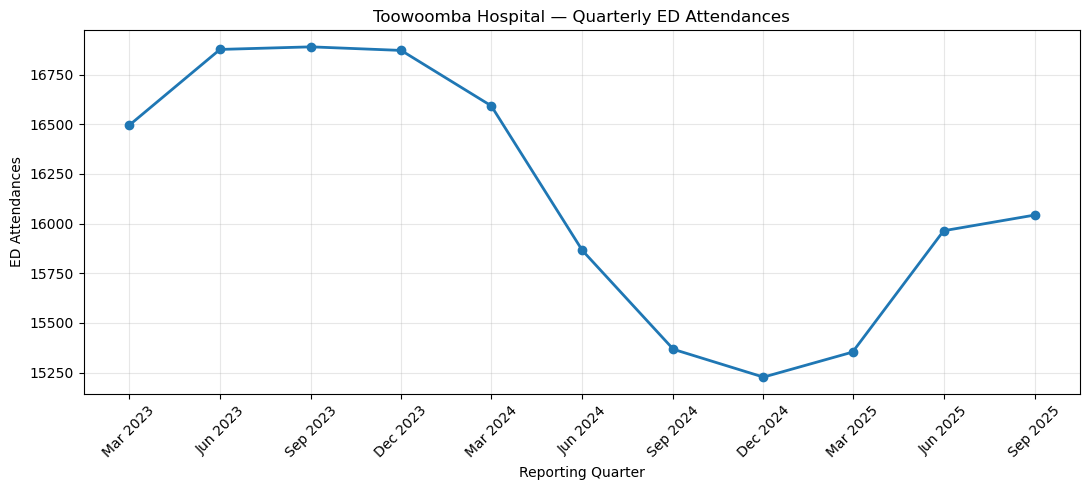

In [4]:
import matplotlib.pyplot as plt
import pandas as pd

# Select quarterly Toowoomba attendance data
df_trend = (
    df_toowoomba
    .select(
        "quarter_end_month",
        "total_attendances"
    )
    .orderBy("quarter_end_month")
    .toPandas()
)

df_trend["quarter_end_month"] = pd.to_datetime(
    df_trend["quarter_end_month"]
)

print(df_trend.to_string(index=False))

# Plot quarterly ED attendances
plt.figure(figsize=(11, 5))

plt.plot(
    df_trend["quarter_end_month"],
    df_trend["total_attendances"],
    marker="o",
    linewidth=2
)

plt.title("Toowoomba Hospital — Quarterly ED Attendances")
plt.xlabel("Reporting Quarter")
plt.ylabel("ED Attendances")
plt.xticks(
    df_trend["quarter_end_month"],
    df_trend["quarter_end_month"].dt.strftime("%b %Y"),
    rotation=45
)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


StatementMeta(, bfda8732-6913-4bf0-872c-1a1814fd5025, 12, Finished, Available, Finished, False)

Trend slope: -136.67 attendances/quarter
R-squared: 0.4965
P-value: 0.0155


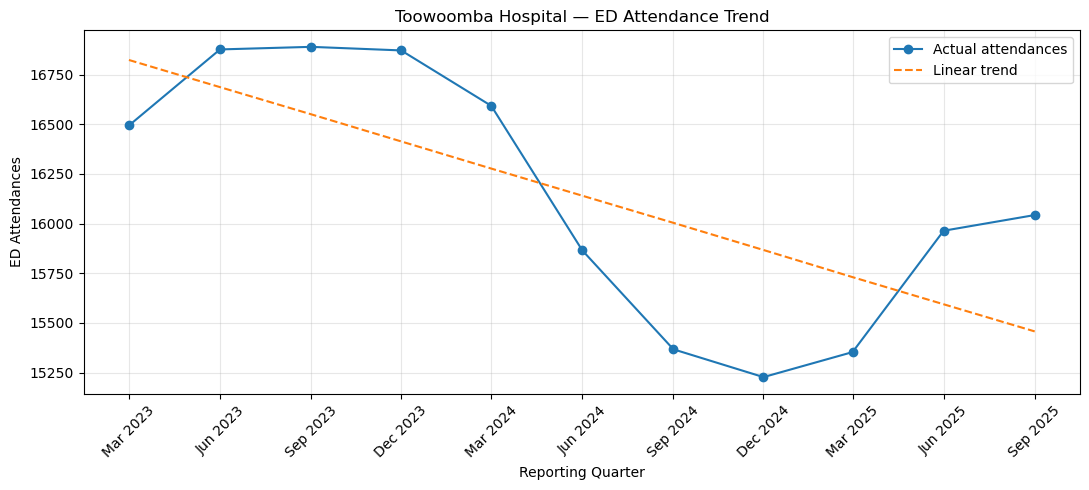

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import linregress

# Sort observations chronologically
df_trend = df_trend.sort_values(
    "quarter_end_month"
).reset_index(drop=True)

# Create sequential quarter index
x = np.arange(len(df_trend))

# Quarterly ED attendances
y = df_trend["total_attendances"].to_numpy(
    dtype=float
)

# Fit ordinary least-squares linear regression
result = linregress(x, y)

slope = result.slope
intercept = result.intercept
r_squared = result.rvalue ** 2
p_value = result.pvalue

# Predicted values from fitted trend
y_pred = intercept + slope * x

print(f"Trend slope: {slope:.2f} attendances/quarter")
print(f"R-squared: {r_squared:.4f}")
print(f"P-value: {p_value:.4f}")

# Plot observations and fitted trend
plt.figure(figsize=(11, 5))

plt.plot(
    df_trend["quarter_end_month"],
    y,
    marker="o",
    label="Actual attendances"
)

plt.plot(
    df_trend["quarter_end_month"],
    y_pred,
    linestyle="--",
    label="Linear trend"
)

plt.title("Toowoomba Hospital — ED Attendance Trend")
plt.xlabel("Reporting Quarter")
plt.ylabel("ED Attendances")
plt.xticks(
    df_trend["quarter_end_month"],
    df_trend["quarter_end_month"].dt.strftime("%b %Y"),
    rotation=45
)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [6]:
from scipy.stats import linregress
import numpy as np
import pandas as pd

# Select Toowoomba clinical indicators
df_clinical = (
    df_toowoomba
    .select(
        "quarter_end_month",
        "seen_within_target_pct",
        "median_wait_minutes",
        "ed_stay_within_4h_pct"
    )
    .orderBy("quarter_end_month")
    .toPandas()
)

indicators = {
    "Treatment Timeliness (%)": "seen_within_target_pct",
    "Median Waiting Time (min)": "median_wait_minutes",
    "ED Stay Within 4 Hours (%)": "ed_stay_within_4h_pct"
}

x = np.arange(len(df_clinical))

results = []

for label, column in indicators.items():
    y = df_clinical[column].to_numpy(dtype=float)

    # Exclude missing observations
    valid = np.isfinite(y)

    if valid.sum() < 3:
        continue

    model = linregress(x[valid], y[valid])

    results.append({
        "Indicator": label,
        "Slope per quarter": round(model.slope, 3),
        "R-squared": round(model.rvalue**2, 4),
        "P-value": round(model.pvalue, 4),
        "Observations": int(valid.sum())
    })

df_clinical_trends = pd.DataFrame(results)

display(df_clinical_trends)


StatementMeta(, bfda8732-6913-4bf0-872c-1a1814fd5025, 14, Finished, Available, Finished, False)

SynapseWidget(Synapse.DataFrame, 413614c2-cb6c-4953-86b6-aa58453ca3ab)

In [7]:
from scipy.stats import pearsonr, spearmanr
import pandas as pd
import numpy as np

# Load Toowoomba data into Pandas
df_corr = (
    df_toowoomba
    .select(
        "quarter_end_month",
        "total_attendances",
        "seen_within_target_pct",
        "median_wait_minutes",
        "ed_stay_within_4h_pct"
    )
    .orderBy("quarter_end_month")
    .toPandas()
)

indicators = {
    "Treatment Timeliness (%)": "seen_within_target_pct",
    "Median Waiting Time (min)": "median_wait_minutes",
    "ED Stay Within 4 Hours (%)": "ed_stay_within_4h_pct"
}

results = []

for name, column in indicators.items():

    data = df_corr[
        ["total_attendances", column]
    ].dropna()

    x = data["total_attendances"].to_numpy(dtype=float)
    y = data[column].to_numpy(dtype=float)

    if len(data) < 3 or np.std(x) == 0 or np.std(y) == 0:
        continue

    pearson_r, pearson_p = pearsonr(x, y)
    spearman_r, spearman_p = spearmanr(x, y)

    results.append({
        "Clinical Indicator": name,
        "Pearson r": round(pearson_r, 3),
        "Pearson p-value": round(pearson_p, 4),
        "Spearman rho": round(spearman_r, 3),
        "Spearman p-value": round(spearman_p, 4),
        "Observations": len(data)
    })

df_correlations = pd.DataFrame(results)

display(df_correlations)


StatementMeta(, bfda8732-6913-4bf0-872c-1a1814fd5025, 15, Finished, Available, Finished, False)

SynapseWidget(Synapse.DataFrame, a4d938a0-ffc7-40fa-a6cc-fecceeaa70b1)

In [8]:
from scipy.stats import pearsonr
import pandas as pd
import numpy as np

# Chronological order
df_changes = df_corr.sort_values(
    "quarter_end_month"
).copy()

columns = [
    "total_attendances",
    "seen_within_target_pct",
    "median_wait_minutes",
    "ed_stay_within_4h_pct"
]

# Calculate quarter-to-quarter changes
for column in columns:
    df_changes[f"change_{column}"] = (
        df_changes[column].diff()
    )

indicators = {
    "Treatment Timeliness (%)": "seen_within_target_pct",
    "Median Waiting Time (min)": "median_wait_minutes",
    "ED Stay Within 4 Hours (%)": "ed_stay_within_4h_pct"
}

results = []

for name, column in indicators.items():

    data = df_changes[
        [
            "change_total_attendances",
            f"change_{column}"
        ]
    ].dropna()

    x = data["change_total_attendances"].to_numpy(dtype=float)
    y = data[f"change_{column}"].to_numpy(dtype=float)

    if len(data) < 3 or np.std(x) == 0 or np.std(y) == 0:
        continue

    r, p = pearsonr(x, y)

    results.append({
        "Indicator": name,
        "Change correlation (r)": round(r, 3),
        "P-value": round(p, 4),
        "Observations": len(data)
    })

df_change_correlations = pd.DataFrame(results)

display(df_change_correlations)


StatementMeta(, bfda8732-6913-4bf0-872c-1a1814fd5025, 16, Finished, Available, Finished, False)

SynapseWidget(Synapse.DataFrame, 89e5beac-f5cd-400e-831b-2248c38d6c51)

In [9]:
# Save Toowoomba descriptive statistics
(
    df_statistics
    .withColumn("facility_code", F.lit(104))
    .write
    .format("delta")
    .mode("overwrite")
    .saveAsTable("gold_ed_descriptive_statistics")
)

# Verify the saved table
df_saved = spark.table("gold_ed_descriptive_statistics")

print("Saved records:", df_saved.count())
display(df_saved)


StatementMeta(, bfda8732-6913-4bf0-872c-1a1814fd5025, 17, Finished, Available, Finished, False)

Saved records: 4


SynapseWidget(Synapse.DataFrame, c91b9253-186c-4743-ab9c-5ef23c83a0ed)

In [10]:
import pandas as pd
from scipy.stats import linregress
import numpy as np

# Load Toowoomba's quarterly hospital records
df_trends = (
    df_toowoomba
    .select(
        "quarter_end_month",
        "total_attendances",
        "seen_within_target_pct",
        "median_wait_minutes",
        "ed_stay_within_4h_pct"
    )
    .orderBy("quarter_end_month")
    .toPandas()
)

indicators = {
    "ED Attendances": "total_attendances",
    "Treatment Timeliness (%)": "seen_within_target_pct",
    "Median Waiting Time (min)": "median_wait_minutes",
    "ED Stay Within 4 Hours (%)": "ed_stay_within_4h_pct"
}

results = []

for name, column in indicators.items():
    y = df_trends[column].to_numpy(dtype=float)
    x = np.arange(len(df_trends))

    valid = np.isfinite(y)

    model = linregress(x[valid], y[valid])

    results.append({
        "facility_code": 104,
        "indicator": name,
        "slope_per_quarter": float(model.slope),
        "r_squared": float(model.rvalue ** 2),
        "p_value": float(model.pvalue),
        "observations": int(valid.sum())
    })

df_trend_statistics = spark.createDataFrame(
    pd.DataFrame(results)
)

# Save as a Delta table
(
    df_trend_statistics.write
    .format("delta")
    .mode("overwrite")
    .saveAsTable("gold_ed_trend_statistics")
)

print(
    "Saved records:",
    spark.table("gold_ed_trend_statistics").count()
)

display(
    spark.table("gold_ed_trend_statistics")
)


StatementMeta(, bfda8732-6913-4bf0-872c-1a1814fd5025, 18, Finished, Available, Finished, False)

Saved records: 4


SynapseWidget(Synapse.DataFrame, 5c5ab2d1-2c7b-432c-8609-ecdc31741e95)

In [11]:
import pandas as pd
import numpy as np
from scipy.stats import pearsonr, spearmanr
from pyspark.sql.types import (
    StructType, StructField,
    StringType, IntegerType, DoubleType
)

# Load Toowoomba quarterly data
df_corr_save = (
    df_toowoomba
    .select(
        "quarter_end_month",
        "total_attendances",
        "seen_within_target_pct",
        "median_wait_minutes",
        "ed_stay_within_4h_pct"
    )
    .orderBy("quarter_end_month")
    .toPandas()
)

indicators = {
    "Treatment Timeliness (%)": "seen_within_target_pct",
    "Median Waiting Time (min)": "median_wait_minutes",
    "ED Stay Within 4 Hours (%)": "ed_stay_within_4h_pct"
}

results = []

for name, column in indicators.items():

    # Original quarterly correlation
    original = df_corr_save[
        ["total_attendances", column]
    ].dropna()

    x = original["total_attendances"].to_numpy(dtype=float)
    y = original[column].to_numpy(dtype=float)

    pearson_r, pearson_p = pearsonr(x, y)
    spearman_r, spearman_p = spearmanr(x, y)

    results.append((
        104,
        name,
        "Original quarterly values",
        float(pearson_r),
        float(pearson_p),
        float(spearman_r),
        float(spearman_p),
        int(len(original))
    ))

    # Quarter-to-quarter changes
    changes = original.diff().dropna()

    dx = changes["total_attendances"].to_numpy(dtype=float)
    dy = changes[column].to_numpy(dtype=float)

    change_r, change_p = pearsonr(dx, dy)

    results.append((
        104,
        name,
        "Quarter-to-quarter changes",
        float(change_r),
        float(change_p),
        None,
        None,
        int(len(changes))
    ))

schema = StructType([
    StructField("facility_code", IntegerType(), False),
    StructField("indicator", StringType(), False),
    StructField("analysis_type", StringType(), False),
    StructField("pearson_r", DoubleType(), True),
    StructField("pearson_p_value", DoubleType(), True),
    StructField("spearman_rho", DoubleType(), True),
    StructField("spearman_p_value", DoubleType(), True),
    StructField("observations", IntegerType(), False)
])

df_correlation_statistics = spark.createDataFrame(
    results,
    schema
)

(
    df_correlation_statistics.write
    .format("delta")
    .mode("overwrite")
    .saveAsTable("gold_ed_correlation_statistics")
)

print(
    "Saved records:",
    spark.table("gold_ed_correlation_statistics").count()
)

display(
    spark.table("gold_ed_correlation_statistics")
)


StatementMeta(, bfda8732-6913-4bf0-872c-1a1814fd5025, 19, Finished, Available, Finished, False)

Saved records: 6


SynapseWidget(Synapse.DataFrame, 2624930d-5ff0-4e08-a89b-e4e7e53e3956)